# Part 5 — Trader behaviour (NFT)

**Question.** Do the agents the model assumes (trend followers, mean reverters) exist among real traders? On what horizon do they react, and do some of them predict the market?

**Data.** 2.4 million NFT sales (MultiNFT dataset); main collection Lil Pudgys, control collection Pudgy Penguins. Each sale gives buyer, seller, date and price.

**Outline.**
1. **5.0** Exploration: heavy-tailed distributions, concentration of activity, cleaning.
2. **5.1** Series: collection price (daily median in ETH) and trader inventories.
3. **5.2** Trader classification (Lillo et al.) against chance.
4. **5.3** Strategy stability (transition matrix).
5. **5.4** Traders' reaction horizon, and the link with α and λ.
6. **5.5** Who wins? Gains, predictive power, persistence.
7. **5.6** Back to the model: calibration with the measured horizons.

**Requires** `data/nft/sales.parquet` (see the README). Runtime: about 1 minute.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

In [21]:
import polars as pl
from scipy.stats import chi2_contingency, norm

FILE = "../data/nft/sales.parquet"
COLLECTION = "lilpudgys"     # main collection
CONTROL = "pudgypenguins"    # control collection

all_sales = pl.scan_parquet(FILE)   # lazy: nothing is loaded yet


def load(collection):
    """Sales of one collection, with the price in ETH (null if not paid in ETH or WETH)."""
    return (
        all_sales
        .filter(pl.col("nft_collection") == collection)
        .select(
            pl.col("event_timestamp").alias("timestamp"),
            pl.col("event_timestamp").dt.date().alias("day"),
            pl.col("nft_identifier").alias("nft"),
            "buyer",
            "seller",
            pl.when(pl.col("payment_symbol").is_in(["ETH", "WETH"]))
            .then(pl.col("payment_quantity") / 10 ** pl.col("payment_decimals"))
            .alias("price_eth"),
            pl.col("payment_usd_price").alias("price_usd"),
        )
        .sort("timestamp")
        .collect()
    )


raw = load(COLLECTION)
print(f"{COLLECTION}: {len(raw)} sales, from {raw['day'].min()} to {raw['day'].max()}")
raw.head()

lilpudgys: 149513 sales, from 2021-12-19 to 2025-09-30


timestamp,day,nft,buyer,seller,price_eth,price_usd
datetime[μs],date,str,str,str,f64,f64
2021-12-19 21:41:28,2021-12-19,"""9224""","""1035740b48beb125""","""39220c58869cb60f""",0.3,1176.777759
2021-12-19 23:03:27,2021-12-19,"""9420""","""3106d747ec554c22""","""19d56b8755929a79""",0.085,333.420365
2021-12-19 23:07:02,2021-12-19,"""11725""","""0588a5146d7f92b4""","""7f1e3f2b955ea85e""",0.045,176.516664
2021-12-19 23:07:57,2021-12-19,"""2716""","""5a15cfa4ce7f3e40""","""86386ccf3e9a77f9""",0.03,117.677776
2021-12-19 23:08:13,2021-12-19,"""6091""","""5a15cfa4ce7f3e40""","""fcc3578dd8de547b""",0.029,113.755183


## 5.0 Exploration

**Distributions** of sales per NFT, purchases per buyer, sales per seller. A straight line in log-log signals a power law (heavy tail).

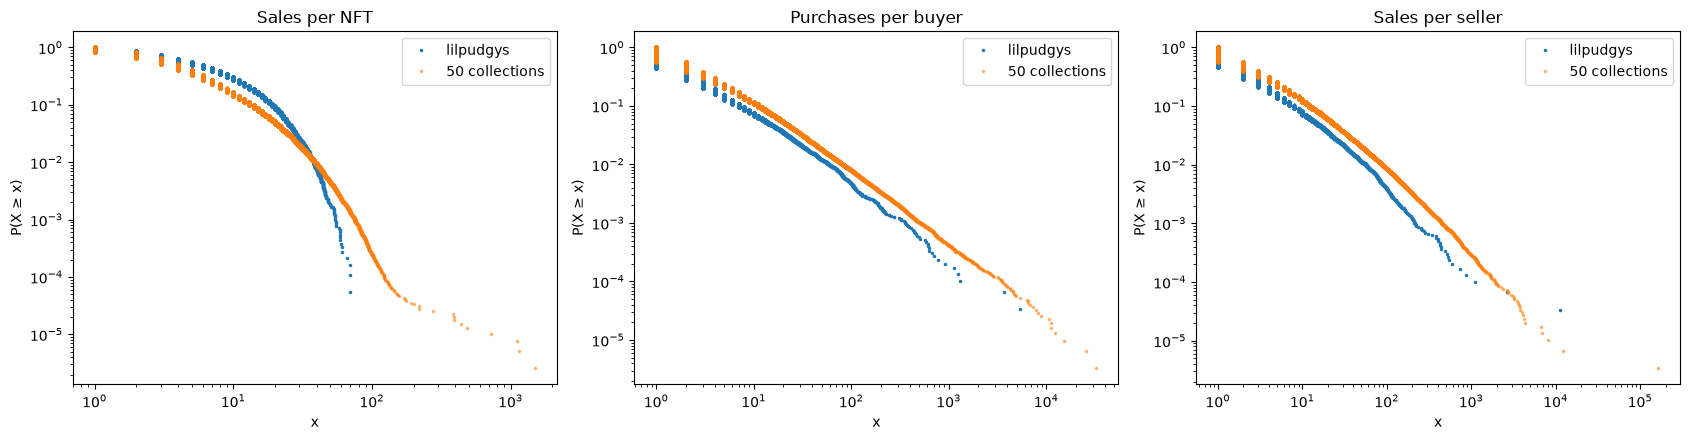

In [22]:
def ccdf(ax, values, **options):
    """CCDF P(X ≥ x) in log-log: sort decreasingly, the k-th value has a fraction k/n above it."""
    x = np.sort(np.asarray(values))[::-1]
    ax.loglog(x, np.arange(1, len(x) + 1) / len(x), **options)


everything = all_sales.select("nft_collection", "nft_identifier", "buyer", "seller")
measures = {
    "Sales per NFT": (
        raw.group_by("nft").len()["len"],
        everything.group_by("nft_collection", "nft_identifier").len().collect()["len"],
    ),
    "Purchases per buyer": (
        raw.group_by("buyer").len()["len"],
        everything.group_by("buyer").len().collect()["len"],
    ),
    "Sales per seller": (
        raw.group_by("seller").len()["len"],
        everything.group_by("seller").len().collect()["len"],
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (title, (one, all_coll)) in zip(axes, measures.items()):
    ccdf(ax, one, marker=".", ls="none", ms=3, label=COLLECTION)
    ccdf(ax, all_coll, marker=".", ls="none", ms=3, alpha=0.5, label="50 collections")
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("P(X ≥ x)")
    ax.legend()
plt.tight_layout()
plt.show()

**Concentration of activity**: each trader counted as buyer and as seller, sorted by number of transactions.

In [23]:
tx_per_trader = (
    pl.concat([raw.select(pl.col("buyer").alias("trader")), raw.select(pl.col("seller").alias("trader"))])
    .group_by("trader").len()
    .sort("len", descending=True)["len"].to_numpy()
)
cum_share = np.cumsum(tx_per_trader) / tx_per_trader.sum()
n_traders = len(tx_per_trader)
print(f"{n_traders} distinct traders")
for q in [0.01, 0.10, 0.50]:
    print(f"The {q:.0%} most active make {cum_share[int(q * n_traders) - 1]:.0%} of transactions")
print(f"Traders with a single transaction: {np.mean(tx_per_trader == 1):.0%}")

38133 distinct traders
The 1% most active make 37% of transactions
The 10% most active make 69% of transactions
The 50% most active make 91% of transactions
Traders with a single transaction: 31%


**Activity over time.**

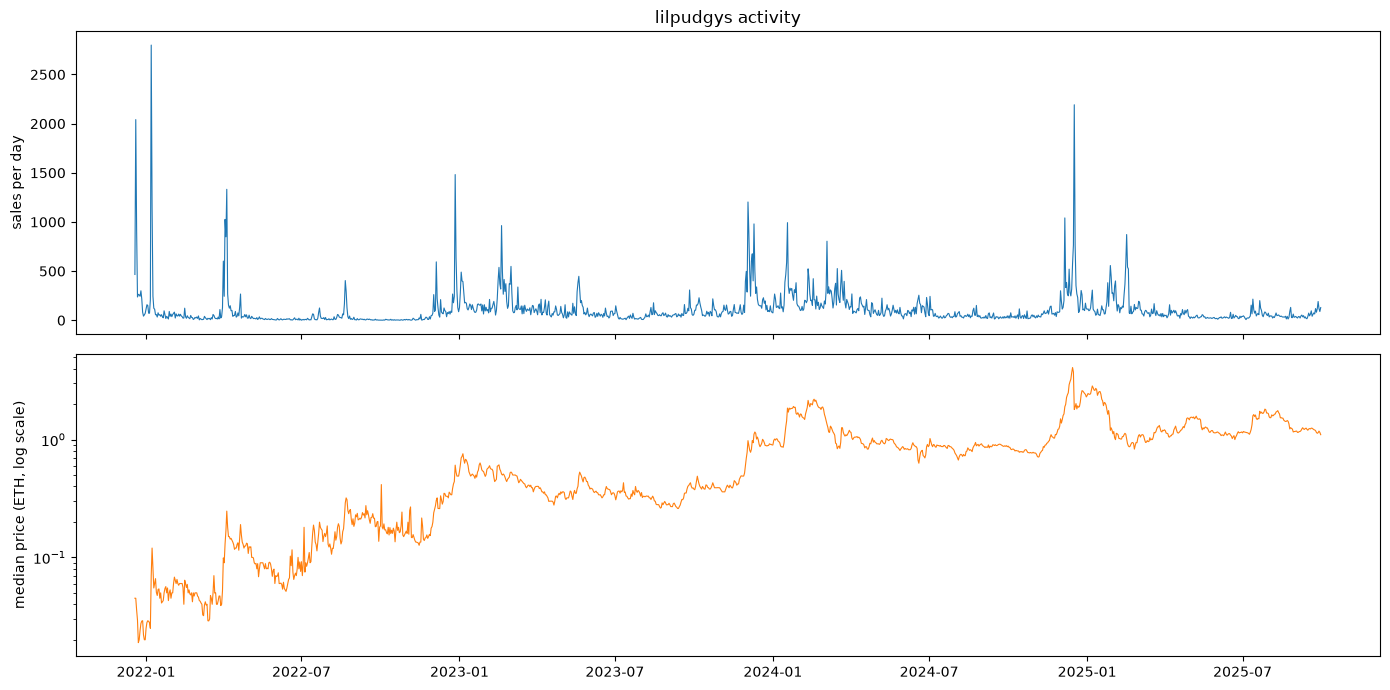

Sales per day: mean 108, median 61
Days without any sale: 3 of 1382


In [24]:
activity = (
    raw.group_by("day")
    .agg(pl.len().alias("sales"), pl.col("price_eth").median().alias("median_price_eth"))
    .sort("day")
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax1.plot(activity["day"], activity["sales"], lw=0.8)
ax1.set_ylabel("sales per day")
ax1.set_title(f"{COLLECTION} activity")
ax2.semilogy(activity["day"], activity["median_price_eth"], lw=0.8, color="tab:orange")
ax2.set_ylabel("median price (ETH, log scale)")
plt.tight_layout()
plt.show()

print(f"Sales per day: mean {activity['sales'].mean():.0f}, median {activity['sales'].median():.0f}")
calendar = pl.date_range(activity["day"].min(), activity["day"].max(), "1d", eager=True)
print(f"Days without any sale: {len(calendar) - len(activity)} of {len(calendar)}")

**Cleaning**, three rules, reporting how many rows each removes:
1. buyer = seller (obvious wash trading);
2. payment not in ETH or WETH, or zero price;
3. extreme prices of the day (outside the 0.5 % – 99.5 % percentiles): typos, disguised transfers, unrepresentative rare pieces.

In [25]:
def clean(df):
    """Remove suspicious sales and report how many rows each rule removes."""
    removed = {}
    n = len(df)
    df = df.filter(pl.col("buyer") != pl.col("seller"))
    removed["buyer = seller"] = n - len(df)

    n = len(df)
    df = df.filter(pl.col("price_eth").is_not_null() & (pl.col("price_eth") > 0))
    removed["payment not in ETH/WETH, or zero price"] = n - len(df)

    n = len(df)
    limits = df.group_by("day").agg(
        pl.col("price_eth").quantile(0.005).alias("low"),
        pl.col("price_eth").quantile(0.995).alias("high"),
    )
    df = (
        df.join(limits, on="day")
        .filter((pl.col("price_eth") >= pl.col("low")) & (pl.col("price_eth") <= pl.col("high")))
        .drop("low", "high")
        .sort("timestamp")
    )
    removed["extreme price of the day (outside 0.5 % – 99.5 %)"] = n - len(df)

    for rule, count in removed.items():
        print(f"  {rule:55s}: {count} rows removed")
    print(f"  {len(df)} sales left")
    return df


cleaned = clean(raw)

  buyer = seller                                         : 80 rows removed
  payment not in ETH/WETH, or zero price                 : 2 rows removed
  extreme price of the day (outside 0.5 % – 99.5 %)      : 977 rows removed
  148454 sales left


## 5.1 Building the series

**Collection price**: each NFT is unique, so I use the log of the **daily median price in ETH** (in ETH rather than USD, so as not to mix the collection's dynamics with the ETH rate).

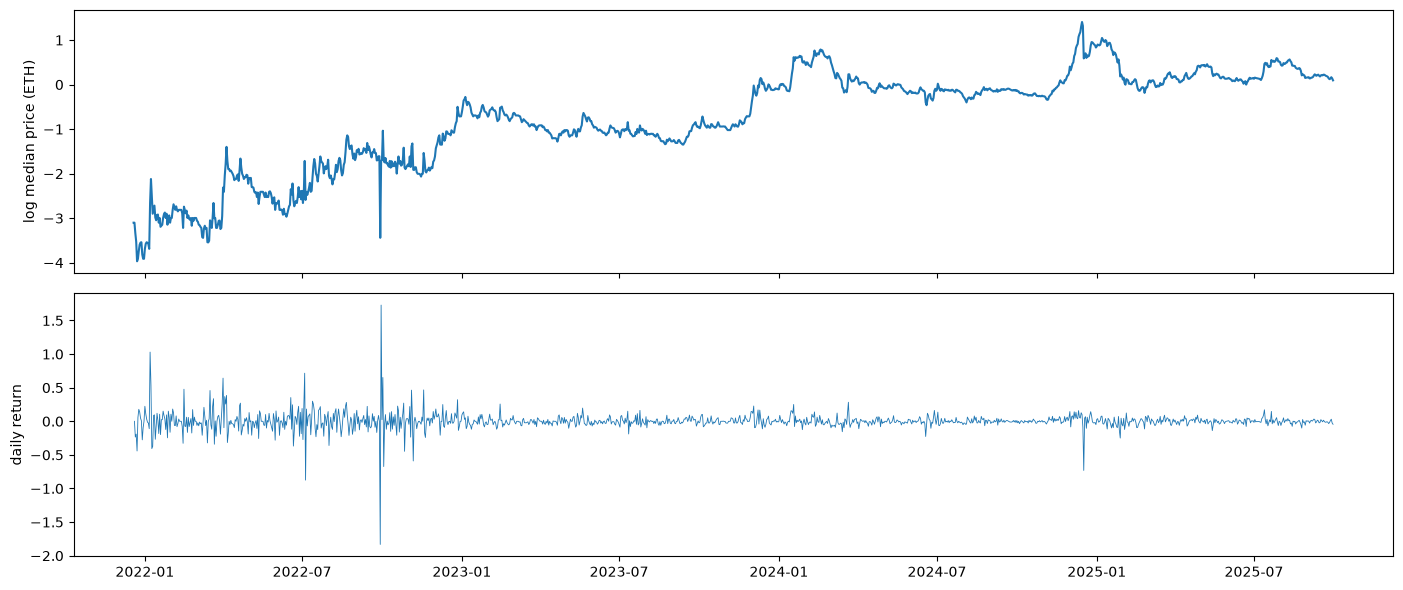

1382 days | std of daily returns: 0.125


In [26]:
def price_series(df):
    """Log of the daily median ETH price on a full calendar (days without sales: last known price)."""
    per_day = df.group_by("day").agg(pl.col("price_eth").log().median().alias("p")).sort("day")
    calendar = pl.DataFrame({"day": pl.date_range(per_day["day"].min(), per_day["day"].max(), "1d", eager=True)})
    return calendar.join(per_day, on="day", how="left").with_columns(pl.col("p").forward_fill())


days = price_series(cleaned)
p = days["p"].to_numpy()
r = np.diff(p, prepend=np.nan)   # r[d] = p[d] − p[d−1]; r[0] does not exist

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax1.plot(days["day"], p)
ax1.set_ylabel("log median price (ETH)")
ax2.plot(days["day"], r, lw=0.6)
ax2.set_ylabel("daily return")
plt.tight_layout()
plt.show()
print(f"{len(p)} days | std of daily returns: {np.nanstd(r):.3f}")

**Inventories**: for each trader, Δv_d = purchases − sales on day d. Long format; only traders with at least 20 active days are kept **before** building their day-by-day series.

In [27]:
def inventories(df, days, min_active_days=20):
    """Inventory changes Δv of active traders.

    Returns a dict trader -> (index of the first day, day-by-day Δv series over the trader's active period).
    """
    # Long format: one row per (trader, day traded). Purchase = +1, sale = −1.
    flows = (
        pl.concat([
            df.select(pl.col("buyer").alias("trader"), "day", pl.lit(1).alias("dv")),
            df.select(pl.col("seller").alias("trader"), "day", pl.lit(-1).alias("dv")),
        ])
        .group_by("trader", "day").agg(pl.col("dv").sum())
        .join(days.with_row_index("d").select("day", "d"), on="day")
    )
    active = flows.group_by("trader").len().filter(pl.col("len") >= min_active_days).select("trader")
    flows = flows.join(active, on="trader")

    dv = {}
    for (trader,), group in flows.group_by("trader"):
        d = group["d"].to_numpy()
        start, end = d.min(), d.max()
        series = np.zeros(end - start + 1)          # 0 on days without transactions
        series[d - start] = group["dv"].to_numpy()
        dv[trader] = (start, series)
    return dv


dv = inventories(cleaned, days)
L = np.array([len(s) for _, s in dv.values()])
print(f"{len(dv)} active traders (at least 20 active days)")
print(f"Active period L: median {np.median(L):.0f} days, from {L.min()} to {L.max()} days")

745 active traders (at least 20 active days)
Active period L: median 461 days, from 27 to 1378 days


## 5.2 Classifying traders (Lillo et al.)

ρ_i = Corr(Δv_{i,d}, r_{d−1}) over the trader's active period of length L_i. Trend follower if ρ_i > 1.96/√L_i, mean reverter if ρ_i < −1.96/√L_i, neutral otherwise. The **previous day's** return is used, to measure the reaction to the price rather than the price impact of one's own trades.

In [28]:
def classify(dv, r, window=None, L_min=30, min_active_days=5):
    """Classify each trader by ρ = Corr(Δv_d, r_{d−1}) over its active period (restricted to `window`)."""
    rows = []
    for trader, (start, series) in dv.items():
        d = np.arange(start, start + len(series))
        keep = d >= 2                             # r_{d−1} must exist (r[0] does not)
        if window is not None:
            keep &= (d >= window[0]) & (d < window[1])
        d, s = d[keep], series[keep]
        if len(s) < L_min or np.count_nonzero(s) < min_active_days:
            continue                               # not enough data for a reliable correlation
        rho = np.corrcoef(s, r[d - 1])[0, 1]
        band = 1.96 / np.sqrt(len(s))
        label = "trend" if rho > band else ("mean reverter" if rho < -band else "neutral")
        rows.append({"trader": trader, "L": len(s), "rho": rho, "z": rho * np.sqrt(len(s)), "class": label})
    return pd.DataFrame(rows)


ORDER = ["trend", "neutral", "mean reverter"]
classes = classify(dv, r)

shares = classes["class"].value_counts(normalize=True).reindex(ORDER).fillna(0)
pd.DataFrame({
    "count": classes["class"].value_counts().reindex(ORDER).fillna(0).astype(int),
    "observed share": shares,
    "expected by chance": [0.025, 0.95, 0.025],
}).round(3)

,count,observed share,expected by chance
class,,,
trend,66,0.089,0.025
neutral,617,0.833,0.950
mean reverter,58,0.078,0.025


If traders ignored prices, z = ρ·√L would be ≈ N(0, 1), giving about 2.5 % trend followers and 2.5 % mean reverters by pure chance.

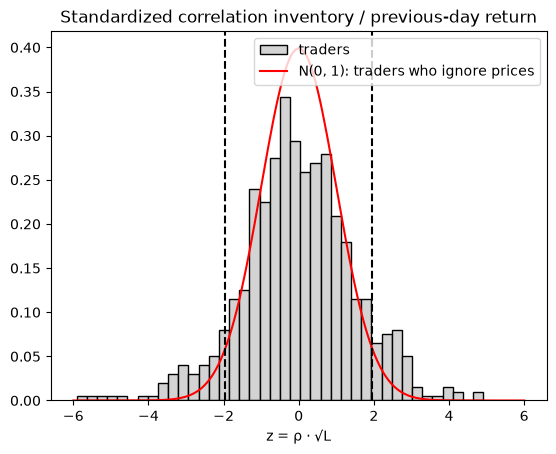

In [29]:
grid = np.linspace(-6, 6, 200)
plt.hist(classes["z"], bins=40, density=True, color="lightgray", edgecolor="k", label="traders")
plt.plot(grid, norm.pdf(grid), "r", label="N(0, 1): traders who ignore prices")
for x in (-1.96, 1.96):
    plt.axvline(x, color="k", ls="--")
plt.xlabel("z = ρ · √L")
plt.title("Standardized correlation inventory / previous-day return")
plt.legend()
plt.show()

## 5.3 Strategy stability

Each trader is classified separately on each half of the period, and class-to-class transitions are counted. If classes were random, all rows of the matrix would be identical.

In [30]:
def transition_matrix(dv, r):
    """Classify each trader on each half of the period, then count transitions."""
    middle = len(r) // 2
    c1 = classify(dv, r, window=(0, middle))
    c2 = classify(dv, r, window=(middle, len(r)))
    both = c1.merge(c2, on="trader", suffixes=("_1", "_2"))   # traders classified in BOTH halves
    return pd.crosstab(both["class_1"], both["class_2"]).reindex(index=ORDER, columns=ORDER, fill_value=0)


counts = transition_matrix(dv, r)
transitions = counts.div(counts.sum(axis=1), axis=0)
expected_by_chance = counts.sum(axis=0) / counts.values.sum()

print(f"{counts.values.sum()} traders classified in both halves\n")
print("Counts (row = class in 1st half, column = class in 2nd half):")
print(counts, "\n")
print("Transition probabilities:")
print(transitions.round(2), "\n")
print("If classes were random, each row would be:")
print(expected_by_chance.round(2).to_frame().T)

chi2_stat, p_value, _, expected = chi2_contingency(counts + 1e-9)
print(f"\nχ² independence test: p-value = {p_value:.3g}")
if (expected < 5).any():
    print("Warning: some expected counts are < 5, the χ² test is then unreliable.")

236 traders classified in both halves

Counts (row = class in 1st half, column = class in 2nd half):
class_2        trend  neutral  mean reverter
class_1                                     
trend              2        4              1
neutral           29      151             33
mean reverter      1       13              2 

Transition probabilities:
class_2        trend  neutral  mean reverter
class_1                                     
trend           0.29     0.57           0.14
neutral         0.14     0.71           0.15
mean reverter   0.06     0.81           0.12 

If classes were random, each row would be:
class_2  trend  neutral  mean reverter
0         0.14     0.71           0.15

χ² independence test: p-value = 0.679


### Control collection

Same functions on another collection: do the conclusions hold?

In [31]:
raw_c = load(CONTROL)
print(f"{CONTROL}: {len(raw_c)} sales")
cleaned_c = clean(raw_c)
days_c = price_series(cleaned_c)
r_c = np.diff(days_c["p"].to_numpy(), prepend=np.nan)
dv_c = inventories(cleaned_c, days_c)
classes_c = classify(dv_c, r_c)
counts_c = transition_matrix(dv_c, r_c)

print(f"\n{len(dv_c)} active traders, {len(classes_c)} classified")
comparison = pd.DataFrame({
    COLLECTION: classes["class"].value_counts(normalize=True).reindex(ORDER).fillna(0),
    CONTROL: classes_c["class"].value_counts(normalize=True).reindex(ORDER).fillna(0),
    "expected by chance": [0.025, 0.95, 0.025],
}).round(3)
print("\nShare of each class:")
print(comparison)
print(f"\nTransition matrix ({CONTROL}):")
print(counts_c.div(counts_c.sum(axis=1), axis=0).round(2))

pudgypenguins: 85861 sales
  buyer = seller                                         : 40 rows removed
  payment not in ETH/WETH, or zero price                 : 38 rows removed
  extreme price of the day (outside 0.5 % – 99.5 %)      : 464 rows removed
  85319 sales left

332 active traders, 330 classified

Share of each class:
               lilpudgys  pudgypenguins  expected by chance
class                                                      
trend              0.089          0.097               0.025
neutral            0.833          0.836               0.950
mean reverter      0.078          0.067               0.025

Transition matrix (pudgypenguins):
class_2        trend  neutral  mean reverter
class_1                                     
trend            0.0     0.75           0.25
neutral          0.1     0.78           0.12
mean reverter    0.0     1.00           0.00


### What 5.0 – 5.3 show

**5.0: a very concentrated market.** 38,000 traders on Lil Pudgys; the top 1 % make 37 % of transactions, the top 10 % 69 %; 31 % trade only once. The CCDFs are power laws, as on traditional financial markets. Cleaning removes < 1 % of sales.

**5.1: a noisy price.** The daily median-price return has a 12.5 % std and a lag-1 autocorrelation of −0.18. Part of it is a **composition effect**: different NFTs (more or less rare) sell each day, so the median moves even when the market does not. This measurement noise cancels from one day to the next, hence the negative autocorrelation. 745 traders have at least 20 active days.

**5.2: trend followers and mean reverters exist, but are few.**

| | Lil Pudgys | Pudgy Penguins | Expected by chance |
|---|---|---|---|
| trend | 8.9 % | 9.7 % | 2.5 % |
| neutral | 83 % | 84 % | 95 % |
| mean reverter | 7.8 % | 6.7 % | 2.5 % |

About **3.5×** more classified traders than chance, with very similar shares in both collections. Both Chiarella populations exist, but most traders do not react detectably to the previous day's return.

**5.3: strategies are not stable.** For the 236 traders classified in both halves, the transition matrix is close to random (χ² p ≈ 0.68; small counts). E.g. 71 % of neutrals stay neutral — exactly the base rate of neutrals in the second half.

> **Correction of the group project**: we had concluded that "strategies are stable" because 87 % of neutrals stayed neutral. I compared this figure with the base rate and the gap disappears: these data do not show that traders keep their strategy.

**Caveat**: the composition noise of the median price (12.5 % a day) dilutes correlations. A robustness check would use a smoother price (3-day rolling median, or a floor price approximated by the daily 10th percentile).

## 5.4 The traders' horizon: the link with α and λ

For each trader and each horizon T from 1 to 100 days, correlate the inventory change with the past T-day return $p_{d-1}-p_{d-1-T}$. T_best is the horizon with the largest absolute correlation.

**Significance**: the max over 100 horizons inflates the correlation even for a random trader. It is compared with the maxima obtained after **circularly shifting** the trader's transactions by a random number of days: this breaks the link with prices but keeps the clustering of trades in time (a plain shuffle would destroy it and make the test too optimistic).

In [32]:
HORIZONS = np.arange(1, 101)   # T = 1 to 100 days
N_SHIFTS = 200                 # number of random shifts for the significance test


def horizon_correlations(series, d, p):
    """Corr(Δv_d, p_{d−1} − p_{d−1−T}) for each horizon T. Also returns the standardized series."""
    S = p[d - 1][:, None] - p[(d - 1)[:, None] - HORIZONS[None, :]]   # (days, horizons): past T-day returns
    S = (S - S.mean(axis=0)) / S.std(axis=0)
    x = (series - series.mean()) / series.std()
    return S.T @ x / len(x), S, x


def trader_horizon(start, series, p, rng_test):
    """T_best (largest absolute correlation) and its significance by circular shifts."""
    d = np.arange(start, start + len(series))
    keep = d - 1 - HORIZONS.max() >= 0          # 100 days of prices needed before each kept day
    d, series = d[keep], series[keep]
    if len(series) < 30 or np.count_nonzero(series) < 5 or series.std() == 0:
        return None
    rho, S, x = horizon_correlations(series, d, p)
    k = np.argmax(np.abs(rho))

    shifts = rng_test.integers(1, len(x), N_SHIFTS)
    X_shift = np.stack([np.roll(x, s) for s in shifts], axis=1)      # (days, N_SHIFTS)
    max_chance = np.abs(S.T @ X_shift / len(x)).max(axis=0)          # max over T, for each shift
    p_value = np.mean(max_chance >= np.abs(rho[k]))
    return {"T_best": HORIZONS[k], "rho_best": rho[k], "p_value": p_value, "L": len(x), "curve": rho}


rng_test = np.random.default_rng(5)
rows = []
for trader, (start, series) in dv.items():
    res_h = trader_horizon(start, series, p, rng_test)
    if res_h is not None:
        rows.append({"trader": trader, **res_h})
horizons = pd.DataFrame(rows)
horizons["significant"] = horizons["p_value"] < 0.05
horizons["type"] = np.where(horizons["rho_best"] > 0, "trend follower", "mean reverter")

print(f"{len(horizons)} traders analysed, {horizons['significant'].sum()} significant "
      f"({horizons['significant'].mean():.0%}, vs 5 % expected by chance)")
horizons[horizons["significant"]].groupby("type")["T_best"].describe()[["count", "25%", "50%", "75%"]]

739 traders analysed, 141 significant (19%, vs 5 % expected by chance)


,count,25%,50%,75%
type,,,,
mean reverter,70.0,3.0,5.0,27.75
trend follower,71.0,2.0,10.0,38.50


**What to look at**: left, the T_best of significant traders against the model's memories (1/α = 10 days, 1/λ = 100 days); right, the mean correlation as a function of T (the shape, not just the maximum).

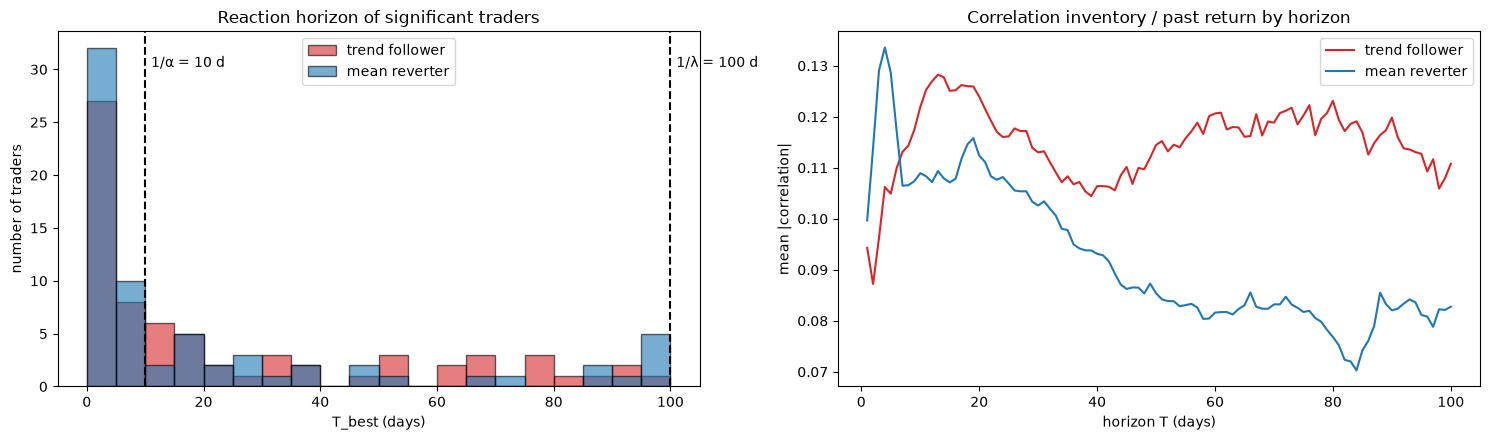

In [33]:
sig = horizons[horizons["significant"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

for kind, colour in [("trend follower", "tab:red"), ("mean reverter", "tab:blue")]:
    axes[0].hist(sig.loc[sig["type"] == kind, "T_best"], bins=np.arange(0, 105, 5), alpha=0.6,
                 color=colour, edgecolor="k", label=kind)
for T_model, name in [(10, "1/α = 10 d"), (100, "1/λ = 100 d")]:
    axes[0].axvline(T_model, color="k", ls="--")
    axes[0].text(T_model + 1, axes[0].get_ylim()[1] * 0.9, name)
axes[0].set_xlabel("T_best (days)")
axes[0].set_ylabel("number of traders")
axes[0].set_title("Reaction horizon of significant traders")
axes[0].legend()

for kind, colour in [("trend follower", "tab:red"), ("mean reverter", "tab:blue")]:
    curves = np.stack(sig.loc[sig["type"] == kind, "curve"].to_numpy())
    axes[1].plot(HORIZONS, np.abs(curves).mean(axis=0), color=colour, label=kind)
axes[1].set_xlabel("horizon T (days)")
axes[1].set_ylabel("mean |correlation|")
axes[1].set_title("Correlation inventory / past return by horizon")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5.5 Who wins? (*smart money*)

**Gain** of a trader at horizon T: $\sum_d \Delta v_{i,d}\,(p_{d+T}-p_d)$, divided by its number of transactions. A log gain (≈ a return), before fees, computed with the daily median price rather than the price actually paid.

In [34]:
def trader_gains(start, series, p, T, window=None):
    """Gain Σ Δv_d (p_{d+T} − p_d) and number of transactions over the active period (restricted to `window`)."""
    d = np.arange(start, start + len(series))
    keep = d + T < len(p)
    if window is not None:
        keep &= (d >= window[0]) & (d < window[1])
    d, s = d[keep], series[keep]
    return np.sum(s * (p[d + T] - p[d])), np.sum(np.abs(s))


rows = []
for trader, (start, series) in dv.items():
    row = {"trader": trader}
    for T in (1, 7, 30):
        gain, n_tx = trader_gains(start, series, p, T)
        row[f"gain_{T}d"] = gain / n_tx if n_tx > 0 else np.nan   # mean gain per transaction (log)
    rows.append(row)
gains = pd.DataFrame(rows).merge(classes[["trader", "class"]], on="trader", how="left")

print("Mean gain per transaction (log, ≈ return), by horizon:")
summary = pd.DataFrame({
    f"T = {T} d": {
        "median": gains[f"gain_{T}d"].median(),
        "mean": gains[f"gain_{T}d"].mean(),
        "share of winning traders": (gains[f"gain_{T}d"] > 0).mean(),
    } for T in (1, 7, 30)
}).round(4)
print(summary)
print("\n7-day gain by class (5.2):")
print(gains.groupby("class")["gain_7d"].agg(["count", "median", "mean"]).reindex(ORDER).round(4))

Mean gain per transaction (log, ≈ return), by horizon:
                          T = 1 d  T = 7 d  T = 30 d
median                    -0.0053  -0.0026   -0.0062
mean                      -0.0055  -0.0011   -0.0126
share of winning traders   0.3812   0.4685    0.4792

7-day gain by class (5.2):
               count  median    mean
class                               
trend             66  0.0039  0.0054
neutral          617 -0.0046 -0.0028
mean reverter     58  0.0075  0.0098


**Predictive power**: correlation between today's inventory change and **tomorrow's** return.

Traders predicting the rise (z > 1.96): 3.9%  | predicting backwards (z < −1.96): 13.2%  | expected by chance: 2.5 % each

Mean z by class (0 = no predictive power):
               count   mean
class                      
trend             66 -0.245
neutral          617 -0.449
mean reverter     58 -0.206


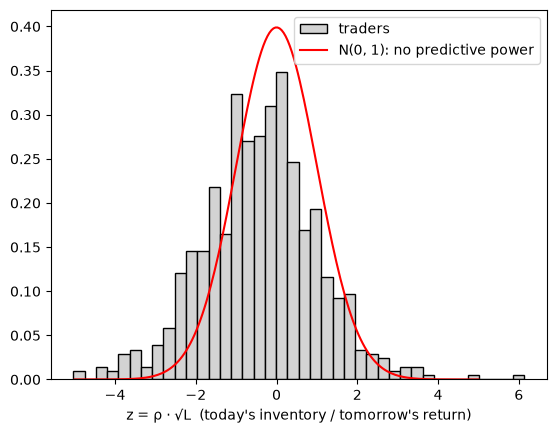

In [35]:
rows = []
for trader, (start, series) in dv.items():
    d = np.arange(start, start + len(series))
    keep = d + 1 < len(r)
    d, s = d[keep], series[keep]
    if len(s) < 30 or np.count_nonzero(s) < 5:
        continue
    rho = np.corrcoef(s, r[d + 1])[0, 1]
    rows.append({"trader": trader, "z_prediction": rho * np.sqrt(len(s))})
prediction = pd.DataFrame(rows).merge(classes[["trader", "class"]], on="trader", how="left")

print(f"Traders predicting the rise (z > 1.96): {(prediction['z_prediction'] > 1.96).mean():.1%}"
      f"  | predicting backwards (z < −1.96): {(prediction['z_prediction'] < -1.96).mean():.1%}"
      f"  | expected by chance: 2.5 % each")
print("\nMean z by class (0 = no predictive power):")
print(prediction.groupby("class")["z_prediction"].agg(["count", "mean"]).reindex(ORDER).round(3))

grid = np.linspace(-5, 5, 200)
plt.hist(prediction["z_prediction"], bins=40, density=True, color="lightgray", edgecolor="k", label="traders")
plt.plot(grid, norm.pdf(grid), "r", label="N(0, 1): no predictive power")
plt.xlabel("z = ρ · √L  (today's inventory / tomorrow's return)")
plt.legend()
plt.show()

**Persistence**: do first-half winners also win in the second half? Spearman correlation (ranks, robust to extreme gains), with a classical and a permutation p-value.

282 traders active in both halves
Spearman correlation between the two halves' gains: -0.047  (p-value: 0.435; permutation: 0.426)


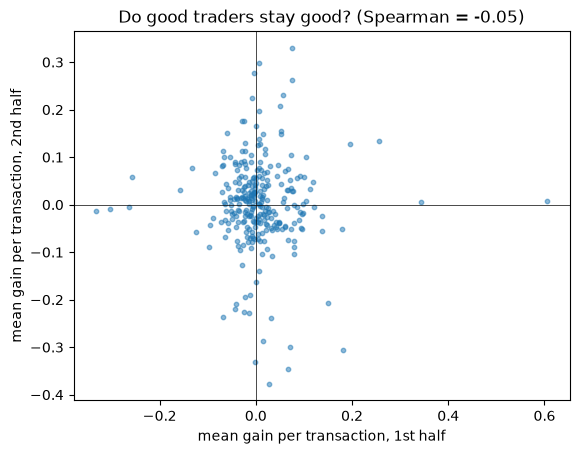

In [36]:
from scipy.stats import spearmanr

# Mean 7-day gain per transaction in each half, for traders active in both
middle = len(p) // 2
rows = []
for trader, (start, series) in dv.items():
    g1, n1 = trader_gains(start, series, p, 7, window=(0, middle))
    g2, n2 = trader_gains(start, series, p, 7, window=(middle, len(p)))
    if n1 >= 5 and n2 >= 5:   # at least 5 transactions in each half
        rows.append({"trader": trader, "gain_1": g1 / n1, "gain_2": g2 / n2})
persistence = pd.DataFrame(rows)

rho_s, p_s = spearmanr(persistence["gain_1"], persistence["gain_2"])

# Permutation test: shuffle second-half gains across traders, breaking any real link
rng_perm = np.random.default_rng(6)
rho_chance = np.array([spearmanr(persistence["gain_1"], rng_perm.permutation(persistence["gain_2"]))[0]
                       for _ in range(2000)])
p_perm = np.mean(np.abs(rho_chance) >= abs(rho_s))

print(f"{len(persistence)} traders active in both halves")
print(f"Spearman correlation between the two halves' gains: {rho_s:+.3f}  "
      f"(p-value: {p_s:.3f}; permutation: {p_perm:.3f})")

plt.scatter(persistence["gain_1"], persistence["gain_2"], s=10, alpha=0.5)
plt.axhline(0, color="k", lw=0.5)
plt.axvline(0, color="k", lw=0.5)
plt.xlabel("mean gain per transaction, 1st half")
plt.ylabel("mean gain per transaction, 2nd half")
plt.title(f"Do good traders stay good? (Spearman = {rho_s:+.2f})")
plt.show()

**Bonus**: use the net buying flow of the best first-half traders to predict the sign of the next-day return in the second half; hit ratio tested against 0.5 (binomial test).

In [37]:
from scipy.stats import binomtest

best = persistence.nlargest(int(0.2 * len(persistence)), "gain_1")["trader"]   # top 20 %


def net_flow(traders, window_start, window_end):
    """Sum of Δv of a group of traders, day by day."""
    flow = np.zeros(len(p))
    for t in traders:
        start, series = dv[t]
        flow[start:start + len(series)] += series
    flow[:window_start] = 0
    flow[window_end:] = 0
    return flow


for name, group in [("top 20 % (1st half)", best), ("all active traders", list(dv.keys()))]:
    flow = net_flow(group, middle, len(p) - 1)
    signal_days = np.nonzero(flow)[0]
    signal_days = signal_days[signal_days + 1 < len(r)]
    hits = np.sum(np.sign(flow[signal_days]) == np.sign(r[signal_days + 1]))
    test = binomtest(int(hits), len(signal_days), 0.5)
    print(f"{name:22s}: hit ratio {hits / len(signal_days):.3f} over {len(signal_days)} days "
          f"(p-value vs 0.5: {test.pvalue:.3f})")

top 20 % (1st half)   : hit ratio 0.431 over 348 days (p-value vs 0.5: 0.012)
all active traders    : hit ratio 0.462 over 653 days (p-value vs 0.5: 0.060)


## 5.6 Back to the model

The horizons measured in 5.4 go back into the Chiarella model: α = 1/(trend followers' horizon), λ = 1/(mean reverters' horizon); κ and β are then calibrated on the Lil Pudgys price with the least squares of Part 4.

In [38]:
sig = horizons[horizons["significant"]]
T_trend = sig.loc[sig["type"] == "trend follower", "T_best"].median()
T_value = sig.loc[sig["type"] == "mean reverter", "T_best"].median()
alpha_nft, lam_nft, gamma_nft = 1 / T_trend, 1 / T_value, 10.0   # γ: a unit convention
print(f"Median horizons: trend {T_trend:.0f} d -> α = {alpha_nft:.3f} | "
      f"mean reverter {T_value:.0f} d -> λ = {lam_nft:.3f}")

# State reconstruction (same equations as Part 4), then least squares r(t+1) = κ F_t + β C_t + ε
m = np.zeros(len(p))
v = np.zeros(len(p))
v[0] = p[0]
for t in range(1, len(p)):
    m[t] = (1 - alpha_nft) * m[t - 1] + alpha_nft * (p[t] - p[t - 1])
    v[t] = (1 - lam_nft) * v[t - 1] + lam_nft * p[t]
x = v - p
skip = 100   # unknown initial state
F = (x[1:-1] ** 3 - x[:-2] ** 3)[skip:]
C = (np.tanh(gamma_nft * m[1:-1]) - np.tanh(gamma_nft * m[:-2]))[skip:]
y = (p[2:] - p[1:-1])[skip:]
X = np.column_stack([F, C])
(kappa_nft, beta_nft), *_ = np.linalg.lstsq(X, y, rcond=None)
residuals_nft = y - X @ np.array([kappa_nft, beta_nft])
cov = residuals_nft.var() * np.linalg.inv(X.T @ X)

print(f"κ̂ = {kappa_nft:+.3f} ± {1.96 * np.sqrt(cov[0, 0]):.3f}   (fundamentalists)")
print(f"β̂ = {beta_nft:+.3f} ± {1.96 * np.sqrt(cov[1, 1]):.3f}   (chartists, with γ = {gamma_nft})")
print(f"Share of return variance explained: {1 - residuals_nft.var() / y.var():.1%}")

Median horizons: trend 10 d -> α = 0.100 | mean reverter 5 d -> λ = 0.200
κ̂ = +0.261 ± 0.053   (fundamentalists)
β̂ = -0.023 ± 0.073   (chartists, with γ = 10.0)
Share of return variance explained: 9.1%


## Conclusion of Part 5

**5.4: short horizons.** 19 % of traders have a significant reaction horizon (5 % expected by chance). Trend followers: median ≈ **12 days** (half between 2 and 50). Mean reverters: median ≈ **5 days** (half between 3 and 21) — they buy after a few days of decline.

**5.5: no detectable smart money.**
- The median trader **loses** ≈ 0.3–0.6 % per transaction (before fees); only 38–48 % of traders win, depending on the horizon.
- 3.9 % of traders predict the next day correctly (2.5 % by chance), but **13 %** predict it *backwards*.
- **No persistence**: Spearman −0.05 (p ≈ 0.45, confirmed by permutation). Performance differences are luck.
- Following the best first-half traders gives a hit ratio of **0.43**, significantly **below** 0.5 (p ≈ 0.01).

*Caveat on the last two points*: the median price has a −0.18 lag-1 autocorrelation (composition noise, plus a bid-ask-bounce-like effect between ETH listings and accepted WETH offers). A trader buying on days when the measured price is high mechanically sees a negative "return" the next day: the negative predictive power may partly come from **price measurement**, not traders.

**5.6: back to the model.**
1. **Both populations exist** but are a minority (≈ 9 % trend followers, 8 % mean reverters, 3.5× chance) and their classes are not stable. Most traders (83 %) do not react detectably to prices; **the model has no counterpart for these neutral traders**, except through the noise ε.
2. **Horizons**: ≈ 12 days for trend followers, i.e. **α ≈ 0.09**, very close to the α = 0.1 used so far; ≈ 5 days for mean reverters, i.e. **λ ≈ 0.2**, far shorter than the assumed λ = 0.01 (100 days). NFT mean reverters are not long-term fundamentalists: they play short-term rebounds.
3. **Trajectory calibration** with these α and λ: κ̂ = 0.26 ± 0.05 (significant), β̂ = −0.03 ± 0.08 (not significant), 9 % of variance explained. The "fundamentalist" term captures a short-term mean reversion that may largely be **median-price measurement noise** — a reminder of the risk of calibrating on a poorly measured series.
4. **Limits**: illiquid market, unique assets (no clean market price), high fees, speculation. The method transfers (classification, horizons, persistence, systematic comparison with chance); the numbers do not.

> **Main message.** The behaviours the model assumes do exist among real traders, but in a minority, on short horizons, without stability or persistent skill. Trader data give orders of magnitude for α and λ that prices alone could not provide — provided the price series is reliable.